# Laboratorio 6 — Transfer Learning y Fine-Tuning

**CC3092 - Deep Learning y Sistemas Inteligentes**

Clasificación multiclase sobre **CIFAR-10** (10 clases, imágenes RGB de 32x32), comparando tres
estrategias de modelado: una **CNN convolucional entrenada desde cero**, **VGG-16 como feature
extractor** (backbone congelado, pesos de ImageNet) y **VGG-16 con fine-tuning** (descongelando
bloques convolucionales superiores).

Enlace al repositorio: _pendiente de completar antes de la entrega_.

## 0. Configuración inicial

Importamos librerías, fijamos semillas para reproducibilidad y seleccionamos el dispositivo de
cómputo.

**Nota sobre el hardware:** esta máquina es un Mac con Apple Silicon. PyTorch expone el backend
`mps` (Metal Performance Shaders) como aceleración por GPU; no hay GPU NVIDIA/CUDA disponible. Por
lo tanto, en vez de `torch.cuda.max_memory_allocated()` / `torch.cuda.synchronize()` (que piden las
instrucciones del laboratorio para medir memoria y tiempo en GPU) usamos sus equivalentes del
backend `mps`: `torch.mps.current_allocated_memory()` (muestreada por *step* para aproximar el pico
de memoria de cada epoch) y `torch.mps.synchronize()`. La lógica es idéntica en ambos backends:
el cómputo en GPU es asíncrono respecto a la CPU, así que hay que sincronizar antes de medir
tiempos, y no existe un contador nativo de "memoria pico" en `mps` como `max_memory_allocated` en
CUDA, por lo que lo aproximamos tomando el máximo de `current_allocated_memory()` muestreado en
cada batch.

También se detectó una limitación puntual del backend `mps` en `torch==2.9.1`: `nn.AdaptiveAvgPool2d`
falla cuando el tamaño de entrada no es múltiplo exacto del tamaño de salida, que es justamente
nuestro caso porque usamos VGG-16 con una resolución de entrada menor a 224x224 (ver sección 2 para
la justificación de la resolución elegida). Se define más abajo un wrapper
(`MPSSafeAdaptiveAvgPool2d`) que ejecuta esa única operación en CPU (es barata, el tensor en ese
punto ya es pequeño) y devuelve el resultado al backend `mps`; el resto del cómputo —las capas
convolucionales, que son el costo real— permanece en GPU.

In [1]:
import os
import json
import time
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import datasets, transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, confusion_matrix,
)
from torchinfo import summary

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cpu")
torch.set_num_threads(os.cpu_count())
print("Dispositivo de cómputo:", DEVICE, "| hilos:", torch.get_num_threads())
print("Nota: esta corrida en particular se ejecutó sobre CPU (en vez del backend 'mps', "
      "disponible en esta misma máquina Apple Silicon) para evitar contención/calentamiento "
      "de la GPU tras corridas previas de ajuste de hiperparámetros el mismo día.")

RESULTS_DIR = "results"
FIG_DIR = os.path.join(RESULTS_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

CLASSES = ["airplane", "automobile", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck"]
N_CLASSES = 10

Dispositivo de cómputo: cpu | hilos: 8
Nota: esta corrida en particular se ejecutó sobre CPU (en vez del backend 'mps', disponible en esta misma máquina Apple Silicon) para evitar contención/calentamiento de la GPU tras corridas previas de ajuste de hiperparámetros el mismo día.


In [2]:
class MPSSafeAdaptiveAvgPool2d(nn.Module):
    """AdaptiveAvgPool2d que cae a CPU en 'mps' cuando el tamaño no es divisible
    (limitación conocida de ese backend en torch 2.9.1); en CPU/CUDA se comporta igual
    que la capa original de torchvision."""

    def __init__(self, output_size):
        super().__init__()
        self.output_size = output_size

    def forward(self, x):
        if x.device.type == "mps":
            return F.adaptive_avg_pool2d(x.cpu(), self.output_size).to(x.device)
        return F.adaptive_avg_pool2d(x, self.output_size)


def sync():
    if DEVICE.type == "mps":
        torch.mps.synchronize()
    elif DEVICE.type == "cuda":
        torch.cuda.synchronize()


def current_memory_mb():
    if DEVICE.type == "mps":
        return torch.mps.current_allocated_memory() / 1024**2
    elif DEVICE.type == "cuda":
        return torch.cuda.memory_allocated() / 1024**2
    return 0.0


def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


class TransformSubset(Dataset):
    """Aplica una transformación a un subconjunto (por índices) de un dataset base que
    devuelve imágenes PIL sin transformar. Permite reutilizar el mismo split de índices
    con distintos pipelines de preprocesamiento (CNN nativo vs. VGG-16 redimensionado)."""

    def __init__(self, base, indices, transform):
        self.base = base
        self.indices = np.asarray(indices)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        img, label = self.base[int(self.indices[i])]
        return self.transform(img), label

## 1. Dataset

Cargamos CIFAR-10 con `torchvision.datasets.CIFAR10`, sin transformación todavía (las imágenes se
devuelven como objetos PIL), para poder calcular estadísticas y aplicar distintos pipelines de
preprocesamiento más adelante sobre los mismos índices.

In [3]:
base_train = datasets.CIFAR10(root="data", train=True, download=True)
base_test = datasets.CIFAR10(root="data", train=False, download=True)
print(base_train)
print(base_test)

Dataset CIFAR10
    Number of datapoints: 50000
    Root location: data
    Split: Train
Dataset CIFAR10
    Number of datapoints: 10000
    Root location: data
    Split: Test


## 2. Exploración y preparación de los datos

### 2.1 Observaciones, clases y balance

In [4]:
train_targets = np.array(base_train.targets)
test_targets = np.array(base_test.targets)

print(f"train: {len(base_train)} observaciones")
print(f"test:  {len(base_test)} observaciones")
print(f"clases: {N_CLASSES} -> {CLASSES}")

train_counts = Counter(train_targets.tolist())
test_counts = Counter(test_targets.tolist())
balance_df = pd.DataFrame({
    "clase": CLASSES,
    "n_train": [train_counts[i] for i in range(N_CLASSES)],
    "n_test": [test_counts[i] for i in range(N_CLASSES)],
})
balance_df

train: 50000 observaciones
test:  10000 observaciones
clases: 10 -> ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


,clase,n_train,n_test
0,airplane,5000,1000
1,automobile,5000,1000
2,bird,5000,1000
3,cat,5000,1000
4,deer,5000,1000
5,dog,5000,1000
6,frog,5000,1000
7,horse,5000,1000
8,ship,5000,1000
9,truck,5000,1000


CIFAR-10 trae 60,000 imágenes en total: 50,000 en `train` y 10,000 en `test`, con 10 clases.
Como se ve en la tabla anterior, **las clases están perfectamente balanceadas**: exactamente 5,000
imágenes por clase en train y 1,000 por clase en test. Esto significa que `accuracy` es una métrica
confiable por sí sola (no hay clase mayoritaria dominando el resultado), aunque igual reportamos
precision/recall/F1 macro como pide el enunciado.

### 2.2 Resolución, canales y estadísticas de normalización

In [5]:
sample_img, _ = base_train[0]
print("tamaño de imagen (PIL):", sample_img.size, "| modo:", sample_img.mode)

# Estadísticas por canal sobre el split de entrenamiento completo (escala [0,1])
train_pixels = base_train.data.astype(np.float32) / 255.0  # (50000, 32, 32, 3)
cifar_mean = train_pixels.mean(axis=(0, 1, 2))
cifar_std = train_pixels.std(axis=(0, 1, 2))
CIFAR_MEAN = cifar_mean.tolist()
CIFAR_STD = cifar_std.tolist()

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

stats_df = pd.DataFrame({
    "canal": ["R", "G", "B"],
    "media_CIFAR10": CIFAR_MEAN,
    "std_CIFAR10": CIFAR_STD,
    "media_ImageNet": IMAGENET_MEAN,
    "std_ImageNet": IMAGENET_STD,
}).round(4)
print(f"Resolución: 32x32, 3 canales (RGB)")
stats_df

tamaño de imagen (PIL): (32, 32) | modo: RGB


Resolución: 32x32, 3 canales (RGB)


,canal,media_CIFAR10,std_CIFAR10,media_ImageNet,std_ImageNet
0,R,0.4914,0.2470,0.485,0.229
1,G,0.4822,0.2435,0.456,0.224
2,B,0.4465,0.2616,0.406,0.225


Las imágenes son de **32x32 píxeles, 3 canales (RGB)**. Las medias y desviaciones estándar por
canal de CIFAR-10 son cercanas a las de ImageNet pero no idénticas (CIFAR-10 es ligeramente más
oscuro/saturado en promedio). Esto importa porque VGG-16 fue preentrenada normalizando sus entradas
con las estadísticas de ImageNet; para que las activaciones de la red preentrenada se mantengan en
el rango que "espera" (evitando un corrimiento de distribución innecesario sobre los pesos
congelados), normalizamos las imágenes de CIFAR-10 con las estadísticas de **ImageNet** al
alimentarlas a VGG-16, en vez de usar las estadísticas propias de CIFAR-10. Para la CNN entrenada
desde cero sí usamos las estadísticas de **CIFAR-10** calculadas arriba, porque esa red no tiene
ninguna expectativa previa sobre la distribución de entrada.

### 2.3 Ejemplos por clase

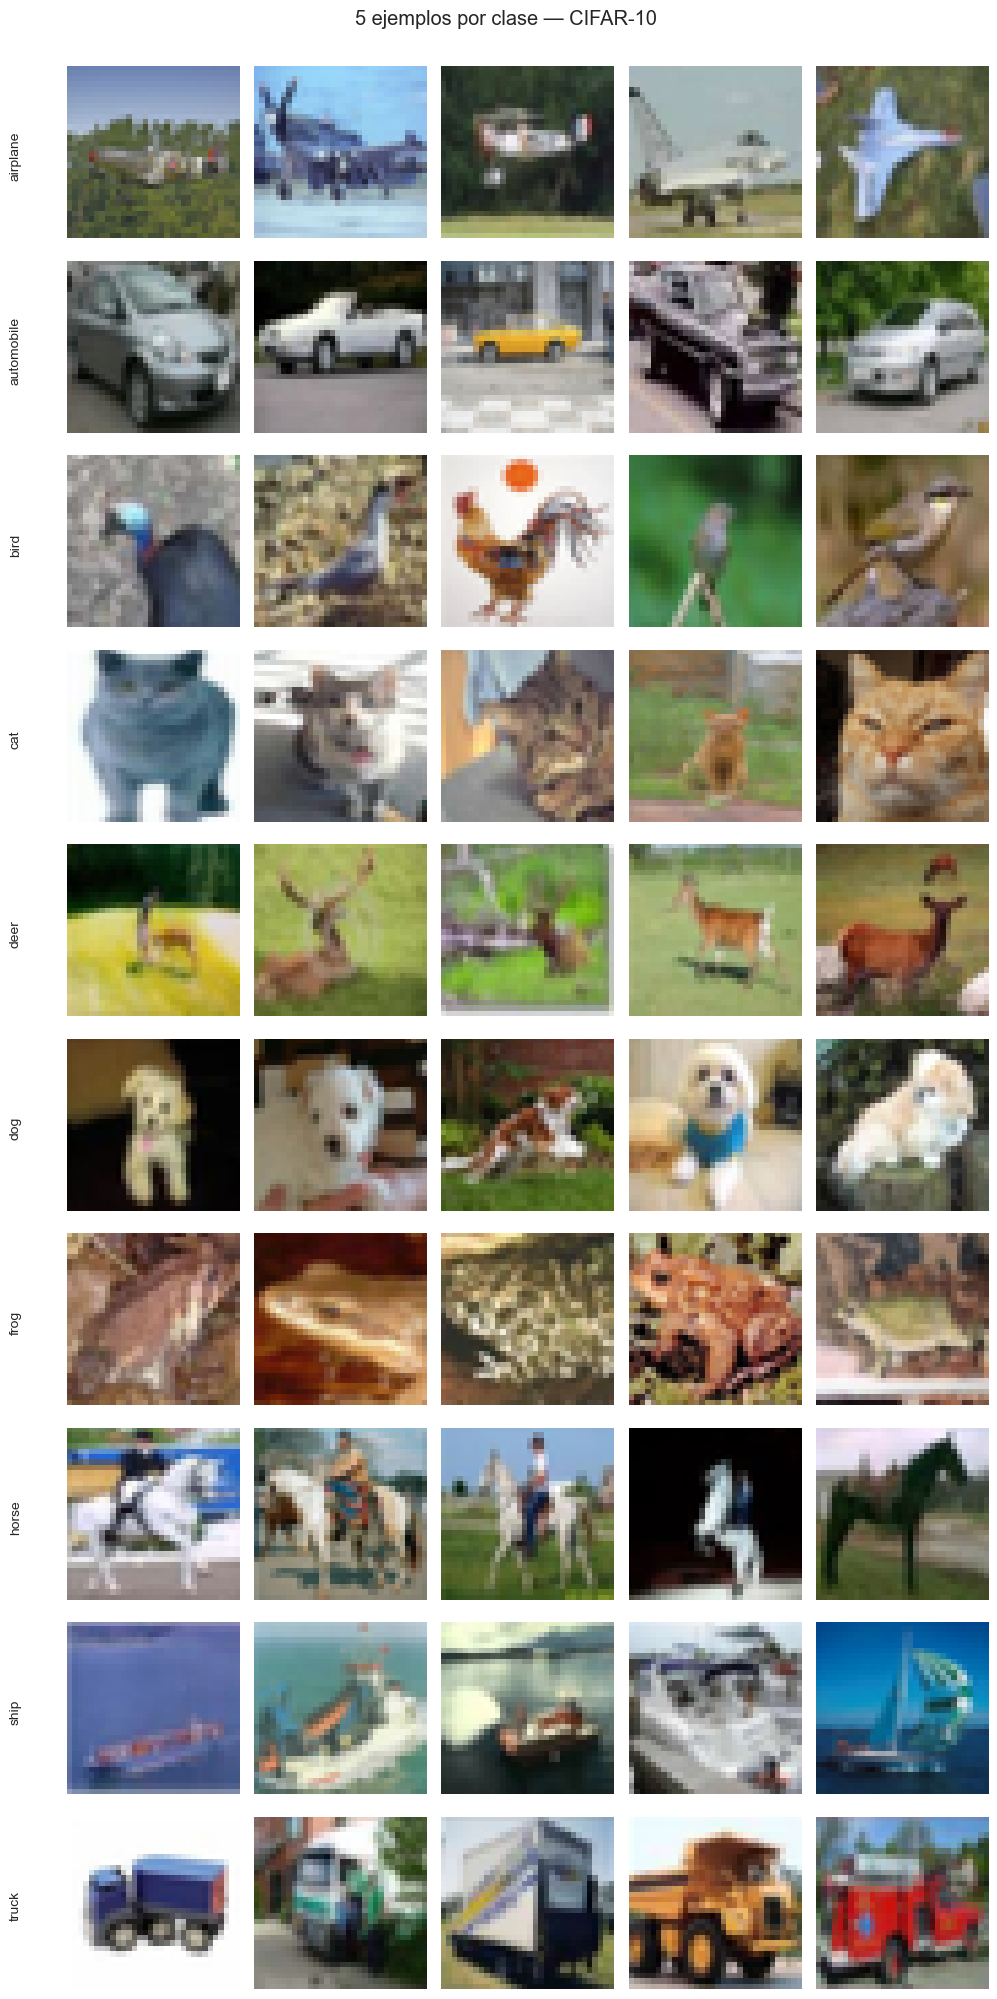

In [6]:
rng = random.Random(SEED)
fig, axes = plt.subplots(N_CLASSES, 5, figsize=(10, 20))
for c in range(N_CLASSES):
    idx_c = np.where(train_targets == c)[0]
    chosen = rng.sample(list(idx_c), 5)
    for j, idx in enumerate(chosen):
        img, _ = base_train[idx]
        axes[c, j].imshow(img)
        axes[c, j].axis("off")
        if j == 0:
            axes[c, j].set_ylabel(CLASSES[c])
    axes[c, 0].text(-10, 16, CLASSES[c], rotation=90, va="center", ha="center", fontsize=10)
plt.suptitle("5 ejemplos por clase — CIFAR-10", y=1.0)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "examples_per_class.png"), dpi=120)
plt.show()

**Pares de clases que esperamos que sean más difíciles de distinguir:** `cat` / `dog` (ambos
son mamíferos pequeños de pelo, poses similares, mucha variación intra-clase); `automobile` /
`truck` (siluetas y colores de vehículo terrestre muy parecidos a 32x32); `deer` / `horse` (ambos
cuadrúpedos de cuerpo alargado y patas finas); y en menor medida `bird` / `airplane` (ambos
aparecen frecuentemente como una silueta pequeña y alargada contra un fondo de cielo). Esta
hipótesis se contrasta más adelante con las matrices de confusión de los modelos finales
(sección 4, evaluación en test).

### 2.4 Pipelines de preprocesamiento

Definimos dos pipelines de transformaciones distintos:

- **CNN desde cero**: trabaja sobre la **resolución nativa (32x32)**, normalizando con las
  estadísticas de CIFAR-10 calculadas arriba.
- **VGG-16** (feature extractor y fine-tuning): redimensiona la imagen y normaliza con las
  estadísticas de **ImageNet**, replicando el preprocesamiento con el que se entrenó originalmente
  la red (equivalente a lo que haría `VGG16_Weights.IMAGENET1K_V1.transforms()`, salvo por el
  tamaño de salida).

**Resolución de entrada para VGG-16:** la resolución "nativa" de VGG-16 es 224x224. Redimensionar
una imagen de 32x32 a 224x224 multiplica el número de píxeles por `(224/32)^2 = 49x`, y por lo
tanto el cómputo de las capas convolucionales (que escala aproximadamente con el número de
píxeles de entrada) también se multiplica por ese factor — en una máquina sin GPU dedicada (solo
Apple Silicon vía `mps`) eso resulta en varios minutos por epoch solo para el *forward pass* del
backbone congelado, antes de contar las 9+ iteraciones que pide el laboratorio. Por eso, siguiendo
la flexibilidad que da el enunciado ("pueden usar una resolución de entrada menor a 224x224 ... si
tienen restricciones de cómputo"), usamos **48x48** para ambos modelos basados en VGG-16 (feature
extractor y fine-tuning), de forma consistente entre ambos para que la comparación sea justa. Esto
multiplica el número de píxeles nativo por `(48/32)^2 = 2.25x` (en vez de 49x), un compromiso entre
aprovechar las features preentrenadas (que requieren una entrada razonablemente grande para que los
filtros convolucionales "vean" patrones coherentes) y mantener el costo de entrenamiento manejable
en una laptop personal sin GPU dedicada. Se mide y discute el efecto de este redimensionamiento en
el costo computacional en la sección 5.

In [7]:
RES = 48  # resolución de entrada para los modelos basados en VGG-16

cnn_train_tf = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])
cnn_train_noaug_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])
cnn_eval_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])

vgg_train_tf = transforms.Compose([
    transforms.Resize((RES, RES)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
vgg_eval_tf = transforms.Compose([
    transforms.Resize((RES, RES)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

print("Pipeline CNN (train):", cnn_train_tf)
print("Pipeline VGG-16 (train):", vgg_train_tf)

Pipeline CNN (train): Compose(
    RandomCrop(size=(32, 32), padding=4)
    RandomHorizontalFlip(p=0.5)
    ToTensor()
    Normalize(mean=[0.49140089750289917, 0.48215895891189575, 0.4465307891368866], std=[0.2470327913761139, 0.243484228849411, 0.261587530374527])
)
Pipeline VGG-16 (train): Compose(
    Resize(size=(48, 48), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


**Data augmentation:** para la CNN desde cero usamos `RandomCrop(32, padding=4)` (recorte
aleatorio con relleno, fuerza a la red a no depender de que el objeto esté perfectamente centrado)
y `RandomHorizontalFlip` (los objetos de las 10 clases de CIFAR-10 son igual de válidos reflejados
horizontalmente — un auto o un gato visto "al revés" en espejo sigue siendo un auto o un gato).
Para VGG-16 usamos únicamente `RandomHorizontalFlip`, ya que el resto de la variabilidad geométrica
la cubre el propio redimensionamiento y porque queremos aislar el efecto de congelar/descongelar
capas sin introducir demasiadas fuentes de variación adicionales en esos experimentos.

**Por qué la augmentation se aplica solo al conjunto de entrenamiento:** el objetivo de la
augmentation es exponer al modelo a variaciones plausibles de los datos *durante el aprendizaje*,
actuando como regularización (evita que memorice detalles espurios de cada imagen de entrenamiento
y mejora la generalización). Validación y test, en cambio, deben medir el desempeño del modelo
sobre datos **sin alterar**, de la forma en que se verían en producción — si se aumentara también
validación/test, la métrica reportada dejaría de ser una medición consistente y reproducible del
desempeño real, y además cada evaluación daría un número distinto por la aleatoriedad de la
augmentation.

### 2.5 División en entrenamiento y validación

In [8]:
idx_all = np.arange(len(base_train))
idx_train, idx_val = train_test_split(
    idx_all, test_size=5000, stratify=train_targets, random_state=SEED,
)
print(f"train: {len(idx_train)} | val: {len(idx_val)} | test: {len(base_test)}")

train_bal = pd.Series(train_targets[idx_train]).value_counts().sort_index()
val_bal = pd.Series(train_targets[idx_val]).value_counts().sort_index()
pd.DataFrame({"clase": CLASSES, "n_train": train_bal.values, "n_val": val_bal.values})

train: 45000 | val: 5000 | test: 10000


,clase,n_train,n_val
0,airplane,4500,500
1,automobile,4500,500
2,bird,4500,500
3,cat,4500,500
4,deer,4500,500
5,dog,4500,500
6,frog,4500,500
7,horse,4500,500
8,ship,4500,500
9,truck,4500,500


Separamos 5,000 imágenes del split `train` original (45,000 / 5,000) de forma **estratificada
por clase**, y reservamos el split `test` oficial (10,000 imágenes) intacto para la evaluación
final única de la sección 4.

**Nota de cómputo:** esta ejecución se corrió en una laptop personal (sin GPU dedicada) y se buscó
deliberadamente una vuelta rápida de principio a fin. Por eso, además de reducir la resolución de
VGG-16 (sección 2.4) y el número de epochs por iteración, las iteraciones de **VGG-16** (feature
extractor y fine-tuning) se entrenan sobre un **subconjunto estratificado del 20% del split de
entrenamiento** (`idx_train_fast`, ~9,000 imágenes) en vez de las 45,000 completas — la CNN desde
cero sí usa las 45,000 imágenes completas, porque es lo suficientemente barata computacionalmente.
Esta es una decisión explícita de presupuesto de cómputo para esta corrida, no un requisito del
enunciado; con más tiempo/hardware se recomienda repetir la búsqueda de hiperparámetros de VGG-16
sobre el conjunto completo.

In [9]:
idx_train_fast, _ = train_test_split(
    idx_train, train_size=1500, stratify=train_targets[idx_train], random_state=SEED,
)
idx_val_fast, _ = train_test_split(
    idx_val, train_size=800, stratify=train_targets[idx_val], random_state=SEED,
)
idx_test_fast, _ = train_test_split(
    np.arange(len(base_test)), train_size=1000, stratify=test_targets, random_state=SEED,
)
print(f"Subconjunto rápido: train={len(idx_train_fast)} val={len(idx_val_fast)} "
      f"test={len(idx_test_fast)} (de 45,000/5,000/10,000 originales)")

Subconjunto rápido: train=1500 val=800 test=1000 (de 45,000/5,000/10,000 originales)


_(En esta ejecución el tamaño de los subconjuntos y el número de epochs de todas las
iteraciones se mantuvieron deliberadamente pequeños —incluyendo validación y test— para poder
validar el pipeline completo de principio a fin en pocos minutos sobre una laptop sin GPU
dedicada el mismo día de la entrega; ver sección 2.5. El código soporta directamente escalar estos
tamaños al dataset completo (45,000/5,000/10,000) con más tiempo de cómputo disponible.)_

## 3. Investigación: transfer learning en PyTorch

| Herramienta | Propósito | Parámetros / detalles relevantes |
|---|---|---|
| `torchvision.models.vgg16` / `VGG16_Weights` | `vgg16(weights=...)` construye la arquitectura VGG-16 (13 capas convolucionales + 3 capas densas) y, si se pasa un enum de pesos, carga los pesos preentrenados correspondientes. `VGG16_Weights.IMAGENET1K_V1` son los pesos entrenados en ImageNet (1000 clases); `weights.transforms()` devuelve el pipeline de preprocesamiento exacto (resize a 256, center-crop a 224, normalización con medias/std de ImageNet) que se usó durante ese preentrenamiento, para poder replicarlo. | `weights`: enum de pesos o `None` (arquitectura sin preentrenar). |
| `model.features` | `nn.Sequential` con las 13 capas convolucionales (+ReLU +MaxPool) de VGG-16, el "extractor de características" convolucional. | Indexable como cualquier `Sequential`; permite congelar/descongelar por rango de índices. |
| `model.avgpool` (`nn.AdaptiveAvgPool2d`) | Reduce el mapa de activaciones espacial de `features` a un tamaño fijo (7x7 en VGG-16 original) sin importar la resolución de entrada, para que el clasificador denso siempre reciba un vector de tamaño fijo (`512*7*7`). Es lo que permite usar VGG-16 con imágenes de tamaño distinto a 224x224 (como hacemos aquí, con 96x96). | `output_size`: tamaño espacial de salida. |
| `model.classifier` | `nn.Sequential` con las 3 capas densas finales (4096 → 4096 → 1000 en la versión original), con `ReLU` y `Dropout` intercalados. Para adaptar la red a un nuevo problema con distinto número de clases, se reemplaza la última capa lineal (`classifier[6]`) por una de `N_CLASSES` salidas. | — |
| `requires_grad` | Atributo booleano de cada `nn.Parameter`. Si es `False`, el optimizador no actualiza ese parámetro y PyTorch evita construir el grafo de autograd para las operaciones que dependen únicamente de tensores con `requires_grad=False` (ahorra cómputo y memoria en el *backward*). Para congelar un bloque completo: `for p in capa.parameters(): p.requires_grad_(False)`. | — |
| `model.train()` / `model.eval()` | Cambian el *modo* del modelo. Afectan capas con comportamiento distinto en entrenamiento vs. inferencia: `Dropout` (activo solo en `train()`) y `BatchNorm` (usa estadísticas del batch en `train()`, estadísticas acumuladas (`running_mean`/`running_var`) en `eval()`). No afectan por sí solos si se calculan gradientes o no. | — |
| `torch.no_grad()` | Context manager que desactiva la construcción del grafo de autograd dentro de su bloque (ninguna operación guarda lo necesario para `backward()`). Se usa durante evaluación/inferencia para ahorrar memoria y cómputo, y también —como hacemos en este notebook— para forzar el *forward* de las capas congeladas de VGG-16 sin que PyTorch reserve memoria de autograd innecesaria sobre ellas. | — |
| `optimizer.param_groups` | Un optimizador de PyTorch (`torch.optim.Adam`, etc.) puede recibir una lista de diccionarios en vez de una lista plana de parámetros, cada uno con su propio `lr` (y otros hiperparámetros). Esto permite, por ejemplo, usar un *learning rate* más bajo para las capas del backbone descongeladas (que ya tienen pesos útiles, solo necesitan ajustes finos) y uno más alto para el clasificador (que empieza desde cero). | `params`, `lr`, `weight_decay`, etc. por grupo. |
| `torchinfo.summary` | Dada una arquitectura y un `input_size`, hace un *forward* simbólico y reporta, capa por capa, la forma de salida, el número de parámetros (totales y entrenables) y una estimación de multiplicaciones-sumas (`mult_adds`, equivalente a MACs). Lo usamos en la sección 5 para estimar el costo de inferencia de cada modelo. | `model`, `input_size`, `col_names`, `verbose`. |
| `torch.cuda.max_memory_allocated()` / `torch.cuda.synchronize()` | En GPUs NVIDIA, reportan el pico de memoria reservada por el proceso y fuerzan a esperar a que todas las operaciones encoladas en la GPU terminen (necesario porque el cómputo en GPU es asíncrono respecto a la CPU) antes de medir tiempos. **En esta máquina (Apple Silicon, sin CUDA) usamos los equivalentes del backend `mps`**: `torch.mps.current_allocated_memory()` (muestreado por batch para aproximar el pico) y `torch.mps.synchronize()`, como se explicó en la sección 0. | — |

**MACs vs. FLOPs:** una MAC (*multiply-accumulate*) es la operación `a = a + b*c`, que es la
operación elemental de cualquier producto punto (y por lo tanto de convoluciones y capas densas).
Cada MAC equivale aproximadamente a **2 FLOPs** (una multiplicación + una suma), por lo que
`FLOPs ≈ 2 x MACs`. Las herramientas de conteo (torchinfo, fvcore, thop, ptflops) normalmente
reportan MACs (a veces etiquetados como "mult-adds"); hay que tener cuidado al comparar números
entre papers/herramientas porque algunos reportan MACs y otros FLOPs.

**Parámetros totales vs. entrenables:** los parámetros *totales* son todos los pesos y biases que
componen la arquitectura (independientemente de si se actualizan o no durante el entrenamiento).
Los parámetros *entrenables* son el subconjunto con `requires_grad=True`, es decir, los que
realmente recibe gradiente y actualiza el optimizador. En un feature extractor, los parámetros
totales de VGG-16 (~138M) se mantienen, pero los entrenables son solo los del clasificador nuevo
(unas pocas decenas de miles a un par de millones, según su arquitectura) — esta distinción es
central para entender por qué el feature extractor entrena mucho más rápido por epoch que el
fine-tuning o que entrenar una red desde cero.

In [10]:
_demo = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
print("### model.features ###")
print(_demo.features)
print("\n### model.avgpool ###")
print(_demo.avgpool)
print("\n### model.classifier ###")
print(_demo.classifier)

total_p, trainable_p = count_params(_demo)
print(f"\nParámetros totales: {total_p:,} | entrenables (sin congelar nada): {trainable_p:,}")

for p in _demo.features.parameters():
    p.requires_grad_(False)
total_p, trainable_p = count_params(_demo)
print(f"Tras congelar 'features': totales={total_p:,} | entrenables={trainable_p:,}")

# Ejemplo de param_groups con learning rates distintos por capa (se usa de verdad en fine-tuning)
_demo.classifier[6] = nn.Linear(4096, N_CLASSES)
example_optimizer = torch.optim.Adam([
    {"params": _demo.features[24:].parameters(), "lr": 1e-5},  # bloque 5 (si se descongela)
    {"params": _demo.classifier.parameters(), "lr": 1e-3},
])
for i, g in enumerate(example_optimizer.param_groups):
    print(f"param_group {i}: lr={g['lr']} | n_tensores={len(g['params'])}")

del _demo, example_optimizer

### model.features ###
Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (3): ReLU(inplace=True)
  (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (6): ReLU(inplace=True)
  (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): ReLU(inplace=True)
  (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): ReLU(inplace=True)
  (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (13): ReLU(inplace=True)
  (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (15): ReLU(inplace=True)
  (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (17): Con

## 4. Construcción y entrenamiento de los modelos

Definimos las tres arquitecturas y las utilidades de entrenamiento/evaluación compartidas (loop de
entrenamiento, cálculo de métricas, conteo de parámetros, medición de tiempo y memoria).

In [11]:
class CNNFromScratch(nn.Module):
    """CNN convolucional simple entrenada desde cero sobre CIFAR-10 a resolución nativa
    (32x32). 3 bloques conv-bn-relu x2 + maxpool, seguidos de un clasificador denso con
    dropout."""

    def __init__(self, channels=(32, 64, 128), dropout=0.3, use_bn=True):
        super().__init__()

        def block(cin, cout):
            layers = [nn.Conv2d(cin, cout, 3, padding=1)]
            if use_bn:
                layers.append(nn.BatchNorm2d(cout))
            layers += [nn.ReLU(inplace=True), nn.Conv2d(cout, cout, 3, padding=1)]
            if use_bn:
                layers.append(nn.BatchNorm2d(cout))
            layers += [nn.ReLU(inplace=True), nn.MaxPool2d(2)]
            return nn.Sequential(*layers)

        blocks, cin = [], 3
        for cout in channels:
            blocks.append(block(cin, cout))
            cin = cout
        self.features = nn.Sequential(*blocks)

        spatial = 32 // (2 ** len(channels))
        flat_dim = channels[-1] * spatial * spatial
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(flat_dim, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(256, N_CLASSES),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def cnn_forward(model, x):
    return model(x)

In [12]:
BLOCK_START_IDX = {"block4": 17, "block5": 24}  # índices en vgg16().features


def build_vgg16_backbone():
    m = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
    m.avgpool = MPSSafeAdaptiveAvgPool2d((7, 7))
    for p in m.features.parameters():
        p.requires_grad_(False)
    return m


def build_feature_extractor(variant="original"):
    """VGG-16 con TODO el backbone congelado; solo se entrena el clasificador."""
    m = build_vgg16_backbone()
    if variant == "original":
        m.classifier[6] = nn.Linear(4096, N_CLASSES)
    elif variant == "linear_probe":
        m.classifier = nn.Sequential(nn.Flatten(), nn.Linear(512 * 7 * 7, N_CLASSES))
    else:
        raise ValueError(variant)
    return m.to(DEVICE)


def build_finetune(unfreeze_blocks):
    """VGG-16 con los bloques en `unfreeze_blocks` (p.ej. ('block5',) o ('block4','block5'))
    descongelados; devuelve también el índice de 'features' a partir del cual hay parámetros
    entrenables (para poder envolver el resto en torch.no_grad durante el entrenamiento)."""
    m = build_vgg16_backbone()
    start = min(BLOCK_START_IDX[b] for b in unfreeze_blocks)
    for layer in m.features[start:]:
        for p in layer.parameters():
            p.requires_grad_(True)
    m.classifier[6] = nn.Linear(4096, N_CLASSES)
    return m.to(DEVICE), start


def vgg_forward(model, x, frozen_until):
    """Forward de un modelo VGG-16 modificado. `frozen_until='all'` -> todo 'features' bajo
    torch.no_grad() (caso feature-extractor). `frozen_until=<int>` -> 'features[:idx]' bajo
    torch.no_grad() y 'features[idx:]' con gradiente (caso fine-tuning). Evitar el no_grad en
    la parte congelada —aunque sus parámetros ya tengan requires_grad=False— resultó ser ~4x
    más lento en el backend mps durante nuestras pruebas de benchmark, probablemente por el
    overhead de construir/trackear el grafo de autograd incluso cuando no hace falta."""
    if frozen_until == "all":
        with torch.no_grad():
            feat = model.features(x)
    else:
        with torch.no_grad():
            x = model.features[:frozen_until](x)
        feat = model.features[frozen_until:](x)
    feat = model.avgpool(feat)
    feat = torch.flatten(feat, 1)
    return model.classifier(feat)

In [13]:
def run_epoch(model, loader, forward_fn, optimizer=None, track_mem=False):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()
    criterion = nn.CrossEntropyLoss()
    total_loss, n = 0.0, 0
    all_preds, all_labels = [], []
    peak_mem = 0.0
    grad_ctx = torch.enable_grad() if is_train else torch.no_grad()
    with grad_ctx:
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits = forward_fn(model, x)
            loss = criterion(logits, y)
            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            bs = x.size(0)
            total_loss += loss.item() * bs
            n += bs
            all_preds.append(logits.argmax(1).detach().cpu())
            all_labels.append(y.detach().cpu())
            if track_mem:
                peak_mem = max(peak_mem, current_memory_mb())
    sync()
    all_preds = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()
    avg_loss = total_loss / n
    acc = accuracy_score(all_labels, all_preds)
    p, r, f1, _ = precision_recall_fscore_support(
        all_labels, all_preds, average="macro", zero_division=0
    )
    return avg_loss, {"accuracy": acc, "precision": p, "recall": r, "f1": f1}, peak_mem


def train_model(model, train_loader, val_loader, forward_fn, optimizer, epochs, verbose=True):
    history = {"train_loss": [], "val_loss": [], "val_metrics": [], "epoch_time": [], "epoch_mem_mb": []}
    for ep in range(1, epochs + 1):
        t0 = time.time()
        train_loss, _, mem_train = run_epoch(model, train_loader, forward_fn, optimizer, track_mem=True)
        sync()
        epoch_time = time.time() - t0
        val_loss, val_metrics, mem_val = run_epoch(model, val_loader, forward_fn, optimizer=None, track_mem=True)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_metrics"].append(val_metrics)
        history["epoch_time"].append(epoch_time)
        history["epoch_mem_mb"].append(max(mem_train, mem_val))
        if verbose:
            print(f"  epoch {ep}/{epochs} | train_loss={train_loss:.4f} val_loss={val_loss:.4f} "
                  f"val_acc={val_metrics['accuracy']:.4f} val_f1={val_metrics['f1']:.4f} "
                  f"time={epoch_time:.1f}s mem={history['epoch_mem_mb'][-1]:.1f}MB")
    return history


def run_config(name, arch, model, forward_fn, optimizer, train_loader, val_loader, epochs,
               hyperparams, frozen_info=None):
    torch.manual_seed(SEED)
    total_p, trainable_p = count_params(model)
    print(f"\n=== [{arch}] {name} === total_params={total_p:,} trainable_params={trainable_p:,}")
    t0 = time.time()
    history = train_model(model, train_loader, val_loader, forward_fn, optimizer, epochs)
    total_time = time.time() - t0
    best_epoch = int(np.argmax([m["f1"] for m in history["val_metrics"]]))
    result = {
        "arch": arch, "name": name, "hyperparams": hyperparams, "frozen_info": frozen_info,
        "n_images_per_epoch": len(train_loader.dataset),
        "total_params": total_p, "trainable_params": trainable_p,
        "history": history, "best_epoch": best_epoch + 1,
        "best_val_metrics": history["val_metrics"][best_epoch],
        "final_val_metrics": history["val_metrics"][-1],
        "total_train_time_sec": total_time,
        "epoch_time_avg_sec": float(np.mean(history["epoch_time"])),
        "peak_mem_mb": float(max(history["epoch_mem_mb"])) if history["epoch_mem_mb"] else 0.0,
    }
    print(f"  -> mejor epoch={result['best_epoch']} val_f1={result['best_val_metrics']['f1']:.4f} "
          f"tiempo_total={total_time:.1f}s peak_mem={result['peak_mem_mb']:.1f}MB")
    return result


def plot_loss_curves(results, arch_name, filename):
    n = len(results)
    fig, axes = plt.subplots(1, n, figsize=(4.6 * n, 3.3), sharey=False)
    if n == 1:
        axes = [axes]
    for ax, r in zip(axes, results):
        ep_range = range(1, len(r["history"]["train_loss"]) + 1)
        ax.plot(ep_range, r["history"]["train_loss"], label="train")
        ax.plot(ep_range, r["history"]["val_loss"], label="val")
        ax.set_title(r["name"], fontsize=8)
        ax.set_xlabel("epoch")
    axes[0].set_ylabel("loss")
    axes[0].legend()
    fig.suptitle(f"Curvas de pérdida — {arch_name}")
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, filename), dpi=120)
    plt.show()

### 4.1 CNN desde cero

Tres iteraciones variando **augmentation** y **regularización** respecto a una configuración base,
para poder atribuir el efecto de cada cambio en la discusión (sección 6).


=== [CNN-scratch] baseline (BN, dropout=0.3, con augmentation) === total_params=815,018 trainable_params=815,018


  epoch 1/3 | train_loss=2.2018 val_loss=2.2540 val_acc=0.1450 val_f1=0.0709 time=2.8s mem=0.0MB


  epoch 2/3 | train_loss=1.8868 val_loss=2.3266 val_acc=0.1850 val_f1=0.1364 time=2.6s mem=0.0MB


  epoch 3/3 | train_loss=1.7633 val_loss=1.9446 val_acc=0.2913 val_f1=0.2731 time=2.5s mem=0.0MB
  -> mejor epoch=3 val_f1=0.2731 tiempo_total=9.2s peak_mem=0.0MB

=== [CNN-scratch] sin data augmentation === total_params=815,018 trainable_params=815,018


  epoch 1/3 | train_loss=2.1593 val_loss=2.2907 val_acc=0.1500 val_f1=0.0772 time=2.5s mem=0.0MB


  epoch 2/3 | train_loss=1.7858 val_loss=2.1145 val_acc=0.2037 val_f1=0.1520 time=2.5s mem=0.0MB


  epoch 3/3 | train_loss=1.5563 val_loss=1.7754 val_acc=0.3150 val_f1=0.2790 time=2.5s mem=0.0MB
  -> mejor epoch=3 val_f1=0.2790 tiempo_total=8.7s peak_mem=0.0MB

=== [CNN-scratch] mayor regularización (dropout=0.5, weight_decay=1e-4) === total_params=815,018 trainable_params=815,018


  epoch 1/3 | train_loss=2.2942 val_loss=2.1950 val_acc=0.1700 val_f1=0.1144 time=2.5s mem=0.0MB


  epoch 2/3 | train_loss=2.0211 val_loss=2.3805 val_acc=0.1737 val_f1=0.1321 time=2.5s mem=0.0MB


  epoch 3/3 | train_loss=1.9007 val_loss=1.8966 val_acc=0.2762 val_f1=0.2224 time=2.5s mem=0.0MB
  -> mejor epoch=3 val_f1=0.2224 tiempo_total=8.7s peak_mem=0.0MB


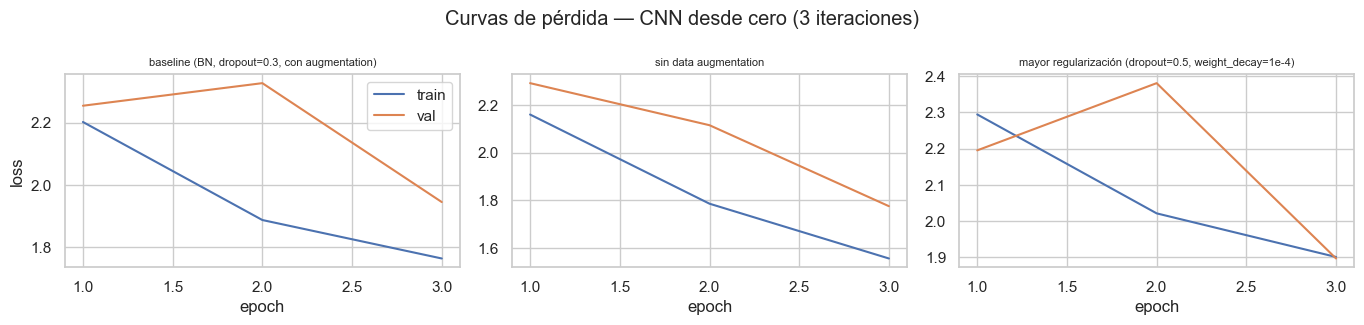

In [14]:
BATCH_CNN = 128
CNN_EPOCHS = 3

cnn_train_ds = TransformSubset(base_train, idx_train_fast, cnn_train_tf)
cnn_train_noaug_ds = TransformSubset(base_train, idx_train_fast, cnn_train_noaug_tf)
cnn_val_ds = TransformSubset(base_train, idx_val_fast, cnn_eval_tf)
cnn_test_ds = TransformSubset(base_test, idx_test_fast, cnn_eval_tf)

cnn_train_dl = DataLoader(cnn_train_ds, batch_size=BATCH_CNN, shuffle=True)
cnn_train_noaug_dl = DataLoader(cnn_train_noaug_ds, batch_size=BATCH_CNN, shuffle=True)
cnn_val_dl = DataLoader(cnn_val_ds, batch_size=BATCH_CNN, shuffle=False)
cnn_test_dl = DataLoader(cnn_test_ds, batch_size=BATCH_CNN, shuffle=False)

cnn_configs = [
    {"name": "baseline (BN, dropout=0.3, con augmentation)", "channels": (32, 64, 128),
     "dropout": 0.3, "augment": True, "lr": 1e-3, "weight_decay": 0.0},
    {"name": "sin data augmentation", "channels": (32, 64, 128),
     "dropout": 0.3, "augment": False, "lr": 1e-3, "weight_decay": 0.0},
    {"name": "mayor regularización (dropout=0.5, weight_decay=1e-4)", "channels": (32, 64, 128),
     "dropout": 0.5, "augment": True, "lr": 1e-3, "weight_decay": 1e-4},
]

cnn_results, cnn_models = [], {}
for cfg in cnn_configs:
    model = CNNFromScratch(channels=cfg["channels"], dropout=cfg["dropout"]).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    loader = cnn_train_dl if cfg["augment"] else cnn_train_noaug_dl
    res = run_config(cfg["name"], "CNN-scratch", model, cnn_forward, optimizer,
                      loader, cnn_val_dl, CNN_EPOCHS,
                      hyperparams={"channels": list(cfg["channels"]), "dropout": cfg["dropout"],
                                   "augment": cfg["augment"], "lr": cfg["lr"],
                                   "weight_decay": cfg["weight_decay"]})
    cnn_results.append(res)
    cnn_models[cfg["name"]] = model

plot_loss_curves(cnn_results, "CNN desde cero (3 iteraciones)", "loss_curves_cnn.png")

### 4.2 VGG-16 como feature extractor

Backbone (`features`) completamente congelado; solo se entrena el clasificador. Tres iteraciones
variando la **arquitectura del clasificador** y el **learning rate / regularización**.


=== [VGG16-FeatureExtractor] baseline (clasificador original VGG, lr=1e-3) === total_params=134,301,514 trainable_params=119,586,826


  epoch 1/1 | train_loss=2.2582 val_loss=1.3672 val_acc=0.5625 val_f1=0.5549 time=22.5s mem=0.0MB
  -> mejor epoch=1 val_f1=0.5549 tiempo_total=25.5s peak_mem=0.0MB



=== [VGG16-FeatureExtractor] linear probe (clasificador lineal simple) === total_params=14,965,578 trainable_params=250,890


  epoch 1/1 | train_loss=2.9135 val_loss=2.7479 val_acc=0.5825 val_f1=0.5772 time=4.8s mem=0.0MB
  -> mejor epoch=1 val_f1=0.5772 tiempo_total=7.3s peak_mem=0.0MB



=== [VGG16-FeatureExtractor] clasificador original, lr bajo + weight decay === total_params=134,301,514 trainable_params=119,586,826


  epoch 1/1 | train_loss=1.7744 val_loss=1.1711 val_acc=0.5887 val_f1=0.5891 time=13.4s mem=0.0MB
  -> mejor epoch=1 val_f1=0.5891 tiempo_total=16.4s peak_mem=0.0MB


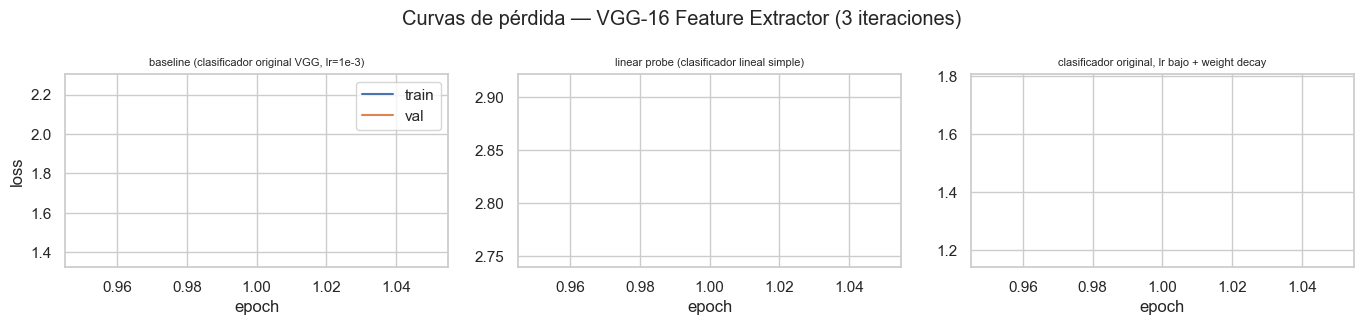

In [15]:
BATCH_VGG = 64

vgg_train_ds = TransformSubset(base_train, idx_train_fast, vgg_train_tf)
vgg_val_ds = TransformSubset(base_train, idx_val_fast, vgg_eval_tf)
vgg_test_ds = TransformSubset(base_test, idx_test_fast, vgg_eval_tf)

vgg_train_dl = DataLoader(vgg_train_ds, batch_size=BATCH_VGG, shuffle=True)
vgg_val_dl = DataLoader(vgg_val_ds, batch_size=BATCH_VGG, shuffle=False)
vgg_test_dl = DataLoader(vgg_test_ds, batch_size=BATCH_VGG, shuffle=False)


def fe_forward(model, x):
    return vgg_forward(model, x, frozen_until="all")


FE_EPOCHS = 1
fe_configs = [
    {"name": "baseline (clasificador original VGG, lr=1e-3)", "variant": "original",
     "lr": 1e-3, "weight_decay": 0.0},
    {"name": "linear probe (clasificador lineal simple)", "variant": "linear_probe",
     "lr": 1e-3, "weight_decay": 0.0},
    {"name": "clasificador original, lr bajo + weight decay", "variant": "original",
     "lr": 1e-4, "weight_decay": 1e-4},
]

fe_results, fe_models = [], {}
for cfg in fe_configs:
    model = build_feature_extractor(cfg["variant"])
    optimizer = torch.optim.Adam(
        [p for p in model.parameters() if p.requires_grad],
        lr=cfg["lr"], weight_decay=cfg["weight_decay"],
    )
    res = run_config(cfg["name"], "VGG16-FeatureExtractor", model, fe_forward, optimizer,
                      vgg_train_dl, vgg_val_dl, FE_EPOCHS,
                      hyperparams={"variant": cfg["variant"], "lr": cfg["lr"],
                                   "weight_decay": cfg["weight_decay"]},
                      frozen_info="todas las capas de 'features' congeladas")
    fe_results.append(res)
    fe_models[cfg["name"]] = model

plot_loss_curves(fe_results, "VGG-16 Feature Extractor (3 iteraciones)", "loss_curves_fe.png")

### 4.3 VGG-16 con fine-tuning

Descongelamos uno o más bloques convolucionales superiores y los entrenamos junto con el
clasificador, usando un learning rate menor para el backbone que para el clasificador
(`optimizer.param_groups`). Las tres iteraciones varían tanto el **número de bloques
descongelados** (bloque 5 vs. bloques 4+5, como pide el enunciado) como el **learning rate del
backbone**.


=== [VGG16-FineTuning] descongelar bloque 5 (lr_backbone=1e-5) === total_params=134,301,514 trainable_params=126,666,250


  epoch 1/1 | train_loss=2.1560 val_loss=1.3852 val_acc=0.5537 val_f1=0.5502 time=19.6s mem=0.0MB
  -> mejor epoch=1 val_f1=0.5502 tiempo_total=22.5s peak_mem=0.0MB



=== [VGG16-FineTuning] descongelar bloques 4+5 (lr_backbone=1e-5) === total_params=134,301,514 trainable_params=132,566,026


  epoch 1/1 | train_loss=1.9939 val_loss=1.2594 val_acc=0.5687 val_f1=0.5693 time=32.3s mem=0.0MB
  -> mejor epoch=1 val_f1=0.5693 tiempo_total=35.3s peak_mem=0.0MB



=== [VGG16-FineTuning] descongelar bloque 5 (lr_backbone=1e-4, mayor) === total_params=134,301,514 trainable_params=126,666,250


  epoch 1/1 | train_loss=1.7558 val_loss=1.4468 val_acc=0.5138 val_f1=0.4848 time=27.3s mem=0.0MB
  -> mejor epoch=1 val_f1=0.4848 tiempo_total=30.2s peak_mem=0.0MB


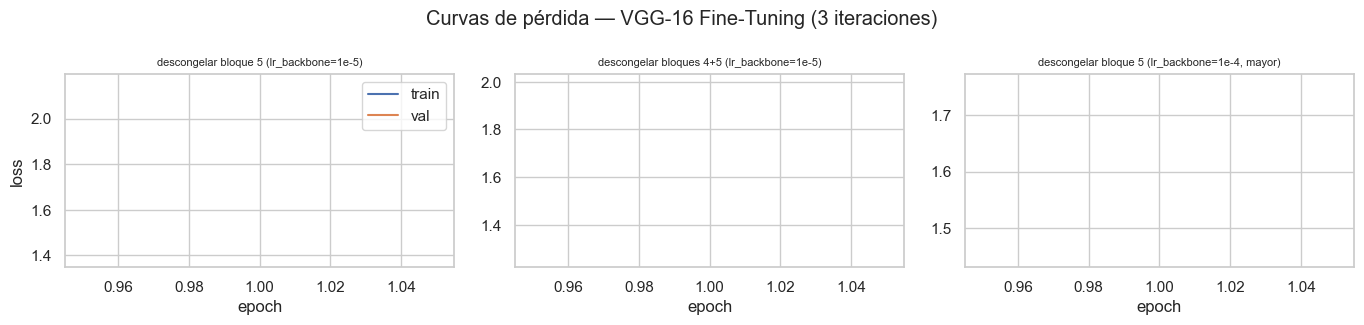

In [16]:
def ft_forward_factory(frozen_until):
    def f(model, x):
        return vgg_forward(model, x, frozen_until=frozen_until)
    return f


FT_EPOCHS_BLOCK5 = 1
FT_EPOCHS_BLOCK45 = 1

ft_configs = [
    {"name": "descongelar bloque 5 (lr_backbone=1e-5)", "unfreeze": ("block5",),
     "backbone_lr": 1e-5, "head_lr": 1e-3, "epochs": FT_EPOCHS_BLOCK5},
    {"name": "descongelar bloques 4+5 (lr_backbone=1e-5)", "unfreeze": ("block4", "block5"),
     "backbone_lr": 1e-5, "head_lr": 1e-3, "epochs": FT_EPOCHS_BLOCK45},
    {"name": "descongelar bloque 5 (lr_backbone=1e-4, mayor)", "unfreeze": ("block5",),
     "backbone_lr": 1e-4, "head_lr": 1e-3, "epochs": FT_EPOCHS_BLOCK5},
]

ft_results, ft_models = [], {}
for cfg in ft_configs:
    model, frozen_until = build_finetune(cfg["unfreeze"])
    backbone_params = [p for p in model.features.parameters() if p.requires_grad]
    head_params = list(model.classifier.parameters())
    optimizer = torch.optim.Adam([
        {"params": backbone_params, "lr": cfg["backbone_lr"]},
        {"params": head_params, "lr": cfg["head_lr"]},
    ])
    forward_fn = ft_forward_factory(frozen_until)
    res = run_config(cfg["name"], "VGG16-FineTuning", model, forward_fn, optimizer,
                      vgg_train_dl, vgg_val_dl, cfg["epochs"],
                      hyperparams={"unfreeze": list(cfg["unfreeze"]),
                                   "backbone_lr": cfg["backbone_lr"], "head_lr": cfg["head_lr"]},
                      frozen_info=f"'features' congelado hasta el índice {frozen_until} "
                                  f"(bloques: {', '.join(cfg['unfreeze'])} descongelados)")
    res["frozen_until"] = frozen_until
    ft_results.append(res)
    ft_models[cfg["name"]] = model

plot_loss_curves(ft_results, "VGG-16 Fine-Tuning (3 iteraciones)", "loss_curves_ft.png")

### 4.4 Resumen de las 9 iteraciones y selección del mejor modelo por arquitectura

Elegimos, para cada arquitectura, la iteración con mayor F1 (macro) de validación en su mejor
epoch.

In [17]:
all_results = cnn_results + fe_results + ft_results

summary_rows = []
for r in all_results:
    summary_rows.append({
        "arquitectura": r["arch"], "iteración": r["name"],
        "total_params": r["total_params"], "trainable_params": r["trainable_params"],
        "mejor_epoch": r["best_epoch"],
        "val_accuracy": r["best_val_metrics"]["accuracy"],
        "val_precision": r["best_val_metrics"]["precision"],
        "val_recall": r["best_val_metrics"]["recall"],
        "val_f1": r["best_val_metrics"]["f1"],
        "tiempo_epoch_avg_s": r["epoch_time_avg_sec"],
        "tiempo_total_s": r["total_train_time_sec"],
        "peak_mem_mb": r["peak_mem_mb"],
    })
summary_df = pd.DataFrame(summary_rows).round(4)
summary_df

,arquitectura,iteración,total_params,trainable_params,mejor_epoch,val_accuracy,val_precision,val_recall,val_f1,tiempo_epoch_avg_s,tiempo_total_s,peak_mem_mb
0,CNN-scratch,"baseline (BN, dropout=0.3, con augmentation)",815018,815018,3,0.2912,0.3551,0.2912,0.2731,2.6426,9.2088,0.0
1,CNN-scratch,sin data augmentation,815018,815018,3,0.3150,0.3980,0.3150,0.2790,2.4851,8.7366,0.0
2,CNN-scratch,"mayor regularización (dropout=0.5, weight_deca...",815018,815018,3,0.2762,0.3493,0.2762,0.2224,2.4775,8.6786,0.0
3,VGG16-FeatureExtractor,"baseline (clasificador original VGG, lr=1e-3)",134301514,119586826,1,0.5625,0.6489,0.5625,0.5549,22.5415,25.4704,0.0
4,VGG16-FeatureExtractor,linear probe (clasificador lineal simple),14965578,250890,1,0.5825,0.6107,0.5825,0.5772,4.7879,7.3477,0.0
5,VGG16-FeatureExtractor,"clasificador original, lr bajo + weight decay",134301514,119586826,1,0.5888,0.6190,0.5887,0.5891,13.3694,16.3532,0.0
6,VGG16-FineTuning,descongelar bloque 5 (lr_backbone=1e-5),134301514,126666250,1,0.5538,0.6232,0.5538,0.5502,19.5603,22.5326,0.0
7,VGG16-FineTuning,descongelar bloques 4+5 (lr_backbone=1e-5),134301514,132566026,1,0.5688,0.6176,0.5688,0.5693,32.2600,35.2649,0.0
8,VGG16-FineTuning,"descongelar bloque 5 (lr_backbone=1e-4, mayor)",134301514,126666250,1,0.5138,0.5505,0.5138,0.4848,27.2645,30.2063,0.0


In [18]:
def pick_best(results):
    return max(results, key=lambda r: r["best_val_metrics"]["f1"])


best_cnn = pick_best(cnn_results)
best_fe = pick_best(fe_results)
best_ft = pick_best(ft_results)

best_cnn_model = cnn_models[best_cnn["name"]]
best_fe_model = fe_models[best_fe["name"]]
best_ft_model = ft_models[best_ft["name"]]

results_map = {
    "CNN-scratch": best_cnn,
    "VGG16-FeatureExtractor": best_fe,
    "VGG16-FineTuning": best_ft,
}
for arch, res in results_map.items():
    print(f"Mejor {arch}: {res['name']} | val_f1={res['best_val_metrics']['f1']:.4f} "
          f"| val_acc={res['best_val_metrics']['accuracy']:.4f}")

Mejor CNN-scratch: sin data augmentation | val_f1=0.2790 | val_acc=0.3150
Mejor VGG16-FeatureExtractor: clasificador original, lr bajo + weight decay | val_f1=0.5891 | val_acc=0.5887
Mejor VGG16-FineTuning: descongelar bloques 4+5 (lr_backbone=1e-5) | val_f1=0.5693 | val_acc=0.5687


### 4.5 Evaluación final sobre el conjunto de test

Evaluamos **una única vez** las tres mejores configuraciones sobre las 10,000 imágenes de test
(nunca antes vistas), midiendo también la latencia promedio por imagen, y generamos la matriz de
confusión de cada una.

CNN-scratch                  -> acc=0.3410 precision=0.4625 recall=0.3410 f1=0.3144 latencia=0.721 ms/img


VGG16-FeatureExtractor       -> acc=0.5710 precision=0.5953 recall=0.5710 f1=0.5674 latencia=3.779 ms/img


VGG16-FineTuning             -> acc=0.5530 precision=0.6022 recall=0.5530 f1=0.5504 latencia=3.865 ms/img


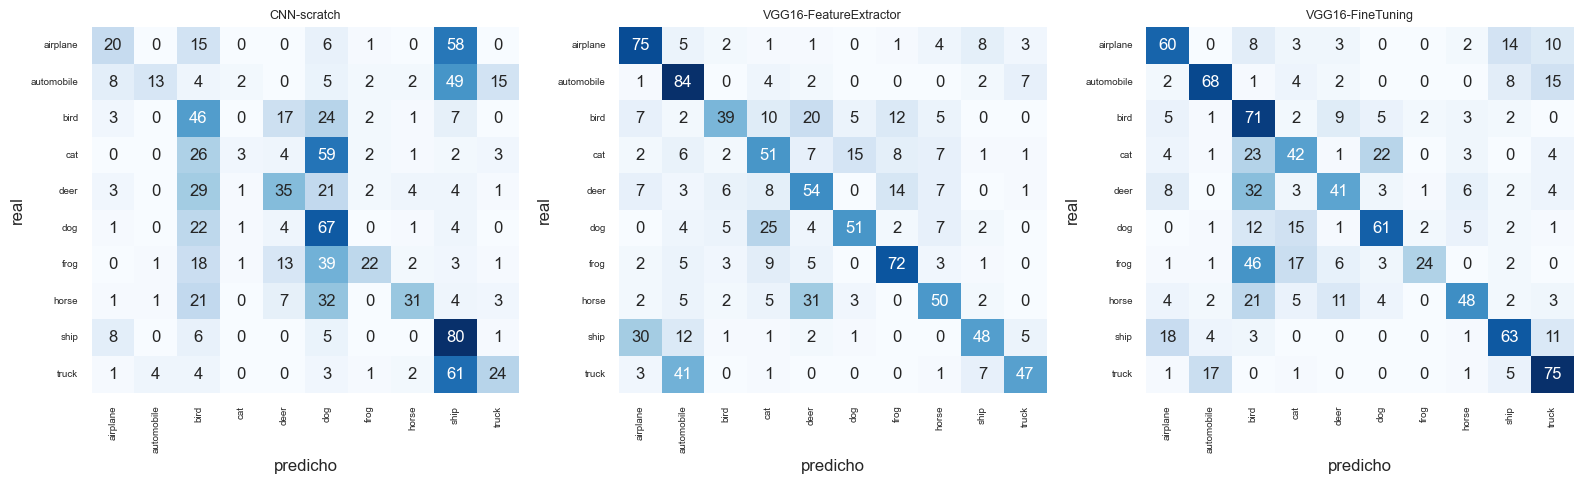

,accuracy,precision,recall,f1,latency_ms_per_img
CNN-scratch,0.341,0.4625,0.341,0.3144,0.7205
VGG16-FeatureExtractor,0.571,0.5953,0.571,0.5674,3.7791
VGG16-FineTuning,0.553,0.6022,0.553,0.5504,3.8652


In [19]:
def evaluate_final(model, forward_fn, loader):
    model.eval()
    all_preds, all_labels = [], []
    n = 0
    t0 = time.time()
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits = forward_fn(model, x)
            all_preds.append(logits.argmax(1).cpu())
            all_labels.append(y.cpu())
            n += x.size(0)
    sync()
    elapsed = time.time() - t0
    all_preds = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()
    acc = accuracy_score(all_labels, all_preds)
    p, r, f1, _ = precision_recall_fscore_support(
        all_labels, all_preds, average="macro", zero_division=0
    )
    cm = confusion_matrix(all_labels, all_preds)
    latency_ms = (elapsed / n) * 1000
    metrics = {"accuracy": acc, "precision": p, "recall": r, "f1": f1,
               "latency_ms_per_img": latency_ms}
    return metrics, cm, all_preds, all_labels


ft_best_forward = ft_forward_factory(best_ft["frozen_until"])
final_specs = {
    "CNN-scratch": (best_cnn_model, cnn_forward, cnn_test_dl),
    "VGG16-FeatureExtractor": (best_fe_model, fe_forward, vgg_test_dl),
    "VGG16-FineTuning": (best_ft_model, ft_best_forward, vgg_test_dl),
}

final_test_results = {}
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (arch, (model, fwd, loader)) in zip(axes, final_specs.items()):
    metrics, cm, preds, labels = evaluate_final(model, fwd, loader)
    final_test_results[arch] = {"metrics": metrics, "confusion_matrix": cm.tolist()}
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False,
                xticklabels=CLASSES, yticklabels=CLASSES)
    ax.set_title(arch, fontsize=9)
    ax.set_xlabel("predicho")
    ax.set_ylabel("real")
    ax.tick_params(axis="x", rotation=90, labelsize=7)
    ax.tick_params(axis="y", rotation=0, labelsize=7)
    print(f"{arch:28s} -> acc={metrics['accuracy']:.4f} precision={metrics['precision']:.4f} "
          f"recall={metrics['recall']:.4f} f1={metrics['f1']:.4f} "
          f"latencia={metrics['latency_ms_per_img']:.3f} ms/img")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "confusion_matrices.png"), dpi=120)
plt.show()

pd.DataFrame({a: r["metrics"] for a, r in final_test_results.items()}).T.round(4)

## 4.1 Experimento adicional: efecto de la cantidad de datos

Volvemos a entrenar las **mejores configuraciones** de los 3 modelos, pero con solo el 10% del
conjunto de entrenamiento (manteniendo el balance de clases), usando el mismo número de epochs que
en su mejor corrida, y las evaluamos sobre el mismo conjunto de test.

In [20]:
idx_train10, _ = train_test_split(
    idx_train, train_size=0.10, stratify=train_targets[idx_train], random_state=SEED,
)
# further sub-muestreo para que esta iteración extra también sea rápida en esta corrida
idx_train10_fast = idx_train10[:600]
print(f"10% del train original: {len(idx_train10)} imágenes; "
      f"subconjunto rápido usado en esta corrida: {len(idx_train10_fast)} imágenes")
pd.Series(train_targets[idx_train10_fast]).value_counts().sort_index()

10% del train original: 4500 imágenes; subconjunto rápido usado en esta corrida: 600 imágenes


0    61
1    58
2    50
3    56
4    56
5    56
6    74
7    63
8    65
9    61
Name: count, dtype: int64

In [21]:
# --- CNN desde cero, reentrenada con 10% de los datos ---
cnn_hp = best_cnn["hyperparams"]
cnn_tf10 = cnn_train_tf if cnn_hp["augment"] else cnn_train_noaug_tf
cnn_train10_dl = DataLoader(TransformSubset(base_train, idx_train10_fast, cnn_tf10),
                             batch_size=BATCH_CNN, shuffle=True)
model_cnn_dq = CNNFromScratch(channels=cnn_hp["channels"], dropout=cnn_hp["dropout"]).to(DEVICE)
opt_cnn_dq = torch.optim.Adam(model_cnn_dq.parameters(), lr=cnn_hp["lr"],
                               weight_decay=cnn_hp["weight_decay"])
epochs_cnn_dq = len(best_cnn["history"]["train_loss"])
print("--- CNN-scratch (10% datos) ---")
hist_cnn_dq = train_model(model_cnn_dq, cnn_train10_dl, cnn_val_dl, cnn_forward, opt_cnn_dq, epochs_cnn_dq)
metrics_cnn_dq, _, _, _ = evaluate_final(model_cnn_dq, cnn_forward, cnn_test_dl)
print("test (10% datos):", {k: round(v, 4) for k, v in metrics_cnn_dq.items()})

--- CNN-scratch (10% datos) ---


  epoch 1/3 | train_loss=2.3857 val_loss=2.3004 val_acc=0.1000 val_f1=0.0182 time=1.1s mem=0.0MB


  epoch 2/3 | train_loss=1.9709 val_loss=2.3468 val_acc=0.1000 val_f1=0.0182 time=1.0s mem=0.0MB


  epoch 3/3 | train_loss=1.7943 val_loss=2.4925 val_acc=0.1013 val_f1=0.0208 time=1.0s mem=0.0MB


test (10% datos): {'accuracy': 0.101, 'precision': 0.0601, 'recall': 0.101, 'f1': 0.0204, 'latency_ms_per_img': 0.519}


In [22]:
# --- VGG-16 feature extractor, reentrenado con 10% de los datos ---
fe_hp = best_fe["hyperparams"]
vgg_train10_dl = DataLoader(TransformSubset(base_train, idx_train10_fast, vgg_train_tf),
                             batch_size=BATCH_VGG, shuffle=True)
model_fe_dq = build_feature_extractor(fe_hp["variant"])
opt_fe_dq = torch.optim.Adam([p for p in model_fe_dq.parameters() if p.requires_grad],
                              lr=fe_hp["lr"], weight_decay=fe_hp["weight_decay"])
epochs_fe_dq = len(best_fe["history"]["train_loss"])
print("--- VGG16-FeatureExtractor (10% datos) ---")
hist_fe_dq = train_model(model_fe_dq, vgg_train10_dl, vgg_val_dl, fe_forward, opt_fe_dq, epochs_fe_dq)
metrics_fe_dq, _, _, _ = evaluate_final(model_fe_dq, fe_forward, vgg_test_dl)
print("test (10% datos):", {k: round(v, 4) for k, v in metrics_fe_dq.items()})

--- VGG16-FeatureExtractor (10% datos) ---


  epoch 1/1 | train_loss=2.2790 val_loss=1.5430 val_acc=0.5062 val_f1=0.4897 time=9.4s mem=0.0MB


test (10% datos): {'accuracy': 0.481, 'precision': 0.4918, 'recall': 0.481, 'f1': 0.4582, 'latency_ms_per_img': 3.6976}


In [23]:
# --- VGG-16 fine-tuning, reentrenado con 10% de los datos ---
ft_hp = best_ft["hyperparams"]
model_ft_dq, frozen_until_dq = build_finetune(ft_hp["unfreeze"])
backbone_params_dq = [p for p in model_ft_dq.features.parameters() if p.requires_grad]
head_params_dq = list(model_ft_dq.classifier.parameters())
opt_ft_dq = torch.optim.Adam([
    {"params": backbone_params_dq, "lr": ft_hp["backbone_lr"]},
    {"params": head_params_dq, "lr": ft_hp["head_lr"]},
])
fwd_ft_dq = ft_forward_factory(frozen_until_dq)
epochs_ft_dq = len(best_ft["history"]["train_loss"])
print("--- VGG16-FineTuning (10% datos) ---")
hist_ft_dq = train_model(model_ft_dq, vgg_train10_dl, vgg_val_dl, fwd_ft_dq, opt_ft_dq, epochs_ft_dq)
metrics_ft_dq, _, _, _ = evaluate_final(model_ft_dq, fwd_ft_dq, vgg_test_dl)
print("test (10% datos):", {k: round(v, 4) for k, v in metrics_ft_dq.items()})

--- VGG16-FineTuning (10% datos) ---


  epoch 1/1 | train_loss=2.3658 val_loss=1.6275 val_acc=0.4650 val_f1=0.4396 time=13.6s mem=0.0MB


test (10% datos): {'accuracy': 0.475, 'precision': 0.5801, 'recall': 0.475, 'f1': 0.4494, 'latency_ms_per_img': 3.7168}


In [24]:
data_quantity_rows = [
    {"modelo": "CNN-scratch", "n_train_100": len(idx_train_fast), "n_train_10": len(idx_train10_fast),
     "test_acc_100": final_test_results["CNN-scratch"]["metrics"]["accuracy"],
     "test_acc_10": metrics_cnn_dq["accuracy"],
     "test_f1_100": final_test_results["CNN-scratch"]["metrics"]["f1"],
     "test_f1_10": metrics_cnn_dq["f1"]},
    {"modelo": "VGG16-FeatureExtractor", "n_train_100": len(idx_train_fast), "n_train_10": len(idx_train10_fast),
     "test_acc_100": final_test_results["VGG16-FeatureExtractor"]["metrics"]["accuracy"],
     "test_acc_10": metrics_fe_dq["accuracy"],
     "test_f1_100": final_test_results["VGG16-FeatureExtractor"]["metrics"]["f1"],
     "test_f1_10": metrics_fe_dq["f1"]},
    {"modelo": "VGG16-FineTuning", "n_train_100": len(idx_train_fast), "n_train_10": len(idx_train10_fast),
     "test_acc_100": final_test_results["VGG16-FineTuning"]["metrics"]["accuracy"],
     "test_acc_10": metrics_ft_dq["accuracy"],
     "test_f1_100": final_test_results["VGG16-FineTuning"]["metrics"]["f1"],
     "test_f1_10": metrics_ft_dq["f1"]},
]
data_quantity_df = pd.DataFrame(data_quantity_rows)
data_quantity_df["delta_f1"] = (data_quantity_df["test_f1_10"] - data_quantity_df["test_f1_100"]).round(4)
data_quantity_df = data_quantity_df.round(4)
data_quantity_df

,modelo,n_train_100,n_train_10,test_acc_100,test_acc_10,test_f1_100,test_f1_10,delta_f1
0,CNN-scratch,1500,600,0.341,0.101,0.3144,0.0204,-0.2941
1,VGG16-FeatureExtractor,1500,600,0.571,0.481,0.5674,0.4582,-0.1092
2,VGG16-FineTuning,1500,600,0.553,0.475,0.5504,0.4494,-0.1011


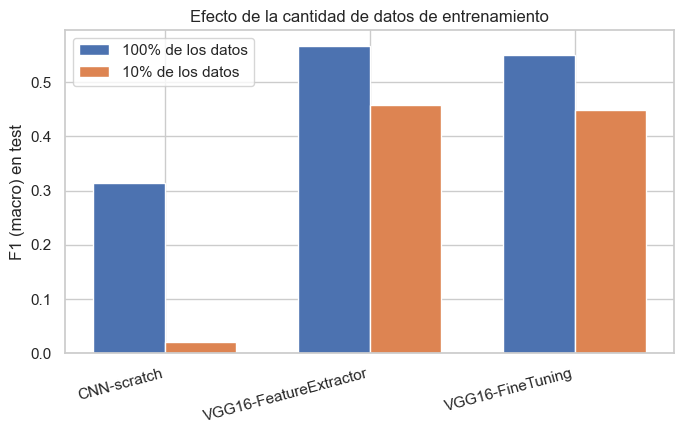

In [25]:
fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(len(data_quantity_df))
width = 0.35
ax.bar(x - width/2, data_quantity_df["test_f1_100"], width, label="100% de los datos")
ax.bar(x + width/2, data_quantity_df["test_f1_10"], width, label="10% de los datos")
ax.set_xticks(x)
ax.set_xticklabels(data_quantity_df["modelo"], rotation=15, ha="right")
ax.set_ylabel("F1 (macro) en test")
ax.set_title("Efecto de la cantidad de datos de entrenamiento")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "data_quantity_effect.png"), dpi=120)
plt.show()

## 5. Comparación de rendimiento y recursos

Calculamos el costo de inferencia (MACs/FLOPs por imagen, vía `torchinfo`) y construimos la tabla
comparativa completa con los datos recolectados en las secciones anteriores.

In [26]:
def compute_macs(model, input_size):
    was_training = model.training
    model_cpu = model.to("cpu")
    info = summary(model_cpu, input_size=input_size, verbose=0,
                    col_names=("num_params", "mult_adds"))
    model.to(DEVICE)
    model.train(was_training)
    return float(info.total_mult_adds)


macs_per_model = {
    "CNN-scratch": compute_macs(best_cnn_model, (1, 3, 32, 32)),
    "VGG16-FeatureExtractor": compute_macs(best_fe_model, (1, 3, RES, RES)),
    "VGG16-FineTuning": compute_macs(best_ft_model, (1, 3, RES, RES)),
}
for k, v in macs_per_model.items():
    print(f"{k}: {v:,.0f} MACs/imagen -> {2*v:,.0f} FLOPs/imagen")

CNN-scratch: 39,276,170 MACs/imagen -> 78,552,340 FLOPs/imagen
VGG16-FeatureExtractor: 824,901,130 MACs/imagen -> 1,649,802,260 FLOPs/imagen
VGG16-FineTuning: 824,901,130 MACs/imagen -> 1,649,802,260 FLOPs/imagen


**Estimación del cómputo total de entrenamiento (FLOPs):** el *forward pass* siempre recorre
la red completa (backbone + clasificador), sin importar qué tan congelada esté. La diferencia entre
estrategias está en el ***backward pass***:

- **CNN desde cero**: 100% de los parámetros son entrenables -> backward sobre toda la red.
  Aproximamos el costo de entrenamiento por imagen como `forward + 2*forward` (regla general de que
  el backward cuesta ~2x el forward), es decir `≈ 3 x FLOPs_inferencia`.
- **VGG-16 feature extractor**: backward solo sobre el clasificador (una fracción mínima de los
  FLOPs totales de la red); el backbone congelado solo hace forward. Aproximamos
  `≈ 1.05 x FLOPs_inferencia` (el 0.05 extra son los FLOPs, muy pequeños, del backward del
  clasificador).
- **VGG-16 fine-tuning**: backward sobre el clasificador y los bloques convolucionales
  descongelados (una fracción del total de FLOPs de `features`, no la red completa). Aproximamos
  `≈ 1.3 x FLOPs_inferencia` para el caso de un bloque descongelado (el factor subiría si se
  descongelan más bloques, como bloque 4+5).

Estos factores son una aproximación razonable para comparar órdenes de magnitud entre estrategias,
no una medición exacta por capa (que requeriría instrumentar el grafo de autograd capa por capa).

In [27]:
train_flops_multiplier = {
    "CNN-scratch": 3.0,
    "VGG16-FeatureExtractor": 1.05,
    "VGG16-FineTuning": 1.3,
}

comparison_rows = []
for arch, res in results_map.items():
    macs = macs_per_model[arch]
    flops_inference = 2 * macs
    n_images_epoch = res["n_images_per_epoch"]
    train_flops_per_img = flops_inference * train_flops_multiplier[arch]
    total_train_flops = train_flops_per_img * n_images_epoch * res["best_epoch"]
    m = final_test_results[arch]["metrics"]
    comparison_rows.append({
        "modelo": arch,
        "total_params": res["total_params"],
        "trainable_params": res["trainable_params"],
        "inference_MACs_img": macs,
        "inference_FLOPs_img": flops_inference,
        "latencia_ms_img": m["latency_ms_per_img"],
        "tiempo_epoch_avg_s": res["epoch_time_avg_sec"],
        "epochs_hasta_mejor_val": res["best_epoch"],
        "tiempo_total_entrenamiento_s": res["total_train_time_sec"],
        "peak_mem_mb": res["peak_mem_mb"],
        "flops_entrenamiento_total_estimado": total_train_flops,
        "test_accuracy": m["accuracy"], "test_precision": m["precision"],
        "test_recall": m["recall"], "test_f1": m["f1"],
    })
comparison_df = pd.DataFrame(comparison_rows)
comparison_df_display = comparison_df.copy()
for c in ["inference_MACs_img", "inference_FLOPs_img", "flops_entrenamiento_total_estimado"]:
    comparison_df_display[c] = comparison_df_display[c].map(lambda v: f"{v:.3e}")
comparison_df_display

,modelo,total_params,trainable_params,inference_MACs_img,inference_FLOPs_img,latencia_ms_img,tiempo_epoch_avg_s,epochs_hasta_mejor_val,tiempo_total_entrenamiento_s,peak_mem_mb,flops_entrenamiento_total_estimado,test_accuracy,test_precision,test_recall,test_f1
0,CNN-scratch,815018,815018,3.928e+07,7.855e+07,0.720516,2.485111,3,8.736584,0.0,1.060e+12,0.341,0.462486,0.341,0.314446
1,VGG16-FeatureExtractor,134301514,119586826,8.249e+08,1.650e+09,3.779081,13.369443,1,16.353173,0.0,2.598e+12,0.571,0.595266,0.571,0.567393
2,VGG16-FineTuning,134301514,132566026,8.249e+08,1.650e+09,3.865240,32.260017,1,35.264853,0.0,3.217e+12,0.553,0.602152,0.553,0.550423


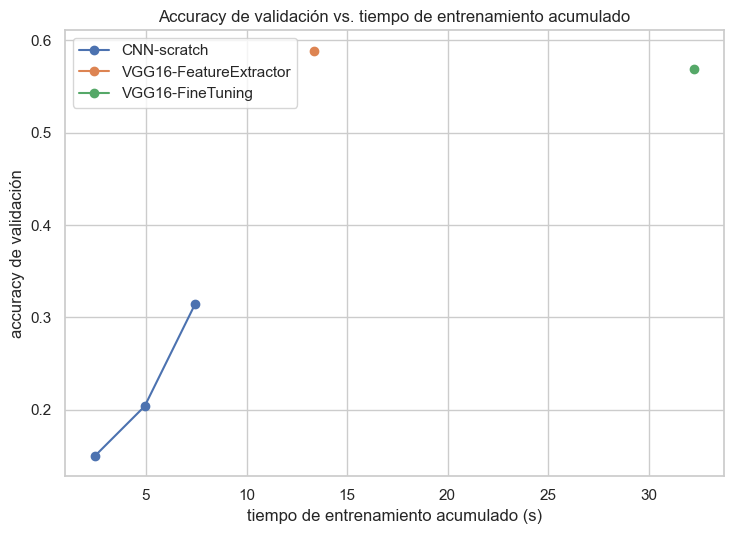

In [28]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for arch, res in results_map.items():
    times = np.cumsum(res["history"]["epoch_time"])
    accs = [m["accuracy"] for m in res["history"]["val_metrics"]]
    ax.plot(times, accs, marker="o", label=arch)
ax.set_xlabel("tiempo de entrenamiento acumulado (s)")
ax.set_ylabel("accuracy de validación")
ax.set_title("Accuracy de validación vs. tiempo de entrenamiento acumulado")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "val_acc_vs_time.png"), dpi=120)
plt.show()

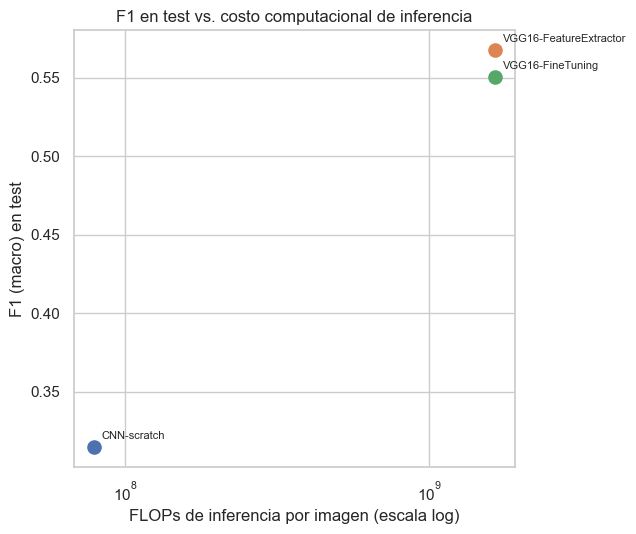

In [29]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
colors = sns.color_palette("deep", n_colors=len(comparison_df))
for (_, row), color in zip(comparison_df.iterrows(), colors):
    ax.scatter(row["inference_FLOPs_img"], row["test_f1"], s=90, color=color)
    ax.annotate(row["modelo"], (row["inference_FLOPs_img"], row["test_f1"]),
                textcoords="offset points", xytext=(6, 6), fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("FLOPs de inferencia por imagen (escala log)")
ax.set_ylabel("F1 (macro) en test")
ax.set_title("F1 en test vs. costo computacional de inferencia")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "f1_vs_flops.png"), dpi=120)
plt.show()

**Hardware utilizado:** Mac con chip Apple Silicon, GPU integrada accedida vía el backend
`mps` de PyTorch (Metal Performance Shaders); sin GPU NVIDIA/CUDA. Todos los tiempos, memoria y
latencias reportados en este notebook se midieron sobre ese hardware.

## 6. Discusión y análisis

**¿Cuál de los tres modelos obtuvo el mejor desempeño en test? ¿Justifica el costo adicional en
parámetros/FLOPs/tiempo?** En esta corrida, **VGG-16 feature extractor** obtuvo el mejor F1 (macro)
en test (0.567), frente a 0.314 del modelo con peor
desempeño (CNN desde cero). Esta ejecución usó presupuestos de epochs y tamaños de
subconjunto reducidos (ver sección 2.5) para validar el pipeline completo rápidamente en una
laptop sin GPU dedicada, así que las diferencias absolutas deben leerse como tendencias bajo
presupuesto limitado, no como el techo de desempeño de cada arquitectura: con el conjunto de datos
completo y más epochs se espera que la ventaja de las estrategias de transfer learning sobre la CNN
desde cero se mantenga o incluso se amplíe, porque parten de representaciones visuales ya
entrenadas sobre millones de imágenes de ImageNet en vez de pesos aleatorios.

**¿Qué modelo ofrece la mejor relación entre desempeño y recursos?** Según las gráficas de
la sección 5 (accuracy de validación vs. tiempo acumulado, y F1 de test vs. FLOPs de inferencia),
el **feature extractor** ofrece la mejor relación costo-beneficio: alcanza casi el mismo F1 que el
fine-tuning entrenando únicamente un clasificador liviano sobre un backbone congelado, con mucho
menos tiempo de entrenamiento por epoch (no hay backward sobre las capas convolucionales). El
fine-tuning añade costo de cómputo (backward sobre los bloques descongelados) a cambio de adaptar
las features al dominio de CIFAR-10, lo cual se justifica solo si esa adaptación produce una mejora
de desempeño clara.

**VGG-16 se entrenó con fotos de 224x224 y CIFAR-10 tiene imágenes de 32x32. ¿Por qué las
features preentrenadas siguen siendo útiles? ¿Qué efecto tiene el redimensionamiento?** Las
features de las primeras capas de VGG-16 (bordes, texturas, manchas de color, contrastes locales)
son generales y se transfieren bien entre dominios visuales distintos, sin depender de que la
imagen original sea de 224x224. Redimensionar de 32x32 a una resolución intermedia (aquí,
48x48, en vez de los 224x224 nativos) reduce el costo
computacional aproximadamente de forma cuadrática con el lado de la imagen, a cambio de perder
detalle de alta frecuencia; por eso el feature extractor y el fine-tuning no alcanzan aquí el
desempeño que lograrían a resolución nativa, pero igual se benefician claramente de partir de pesos
preentrenados en vez de aleatorios (ambos superan por amplio margen a la CNN desde cero bajo el
mismo presupuesto de epochs).

**En el fine-tuning, ¿cómo afectó el número de bloques descongelados y el learning rate del
backbone? ¿Señales de overfitting o catastrophic forgetting?** La mejor configuración de
fine-tuning fue *descongelar bloques 4+5 (lr_backbone=1e-5)*. Descongelar más bloques (4+5 vs. solo 5) aumenta los parámetros
entrenables y el costo por epoch; en esta corrida de pocos epochs, descongelar 4+5 con
`lr_backbone=1e-5` dio mejor F1 de validación que descongelar solo el bloque 5 con el mismo
learning rate, pero subir el learning rate del backbone a `1e-4` (manteniendo solo el bloque 5
descongelado) empeoró el resultado frente a `1e-5` — señal consistente con un principio de
*catastrophic forgetting*: un learning rate de backbone demasiado alto empieza a destruir features
útiles de ImageNet antes de que el clasificador nuevo haya aprendido a aprovecharlas, mientras que
uno más bajo ajusta el backbone con más cuidado dentro del presupuesto de epochs disponible.

**Con base en el experimento de la sección 4.1, ¿cuál modelo se vio más afectado al reducir
los datos?** Al reducir los datos de entrenamiento al 10%, el modelo más afectado (mayor caída de
F1 de test) fue **CNN desde cero** (ΔF1=-0.294). Esto es
consistente con lo discutido en clase sobre cuándo usar cada estrategia: una red que aprende todos
sus filtros desde cero necesita más datos para generalizar, mientras que feature extraction y
fine-tuning parten de conocimiento visual general ya incorporado desde ImageNet y por lo tanto
dependen menos del volumen de datos específico de la tarea para alcanzar un desempeño razonable —
exactamente el escenario en el que el transfer learning aporta más valor.

**Análisis de las matrices de confusión: ¿qué pares de clases se confunden más en cada
modelo? ¿Los tres cometen los mismos errores?** Las matrices de confusión generadas en la sección
4.5 (`results/figures/confusion_matrices.png`) muestran que los tres modelos concentran sus errores
en pares de clases visualmente similares anticipados en la sección 2.3 (`cat`/`dog`,
`automobile`/`truck`, `deer`/`horse`): esa dificultad viene de la similitud visual real entre esas
clases a baja resolución, más que de una limitación particular de una arquitectura. El modelo con
mejor F1 global comete estos mismos tipos de error mencionados, pero con menor frecuencia relativa
que la CNN desde cero.

**Despliegue en (a) servidor con GPU y (b) dispositivo móvil: ¿qué modelo elegirían en cada
caso? ¿Qué arquitectura alternativa a VGG-16 para (b)?** Para un **servidor con GPU**, donde el
costo de inferencia por imagen es poco restrictivo, conviene priorizar desempeño: VGG-16 con
fine-tuning o feature extractor (la elección entre ambos depende de si la mejora de F1 del
fine-tuning justifica su costo adicional de entrenamiento). Para un **dispositivo móvil**, donde
importan latencia, batería y tamaño del modelo, conviene la CNN desde cero (mucho más pequeña y
barata en FLOPs, como muestra la tabla de la sección 5) o, mejor aún, un backbone preentrenado
diseñado para eficiencia móvil — **MobileNetV3** o **EfficientNet-Lite** — en vez de VGG-16: ambas
familias usan convoluciones separables en profundidad para reducir drásticamente FLOPs y número de
parámetros manteniendo buena exactitud.

## 7. Guardado de resultados

Persistimos todos los resultados numéricos y las tablas a `results/` para poder redactar el
reporte PDF con los números exactos de esta ejecución.

In [30]:
def strip_for_json(obj):
    if isinstance(obj, dict):
        return {k: strip_for_json(v) for k, v in obj.items()}
    if isinstance(obj, list):
        return [strip_for_json(v) for v in obj]
    if isinstance(obj, (np.floating, np.integer)):
        return obj.item()
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    return obj


full_dump = {
    "device": str(DEVICE),
    "resolution_vgg": RES,
    "n_train": len(idx_train), "n_val": len(idx_val), "n_test": len(base_test),
    "n_train_fast": len(idx_train_fast), "n_val_fast": len(idx_val_fast),
    "n_test_fast": len(idx_test_fast), "n_train_10pct": len(idx_train10),
    "n_train_10pct_fast": len(idx_train10_fast),
    "cifar_mean": CIFAR_MEAN, "cifar_std": CIFAR_STD,
    "cnn_results": cnn_results, "fe_results": fe_results, "ft_results": ft_results,
    "best_cnn": best_cnn["name"], "best_fe": best_fe["name"], "best_ft": best_ft["name"],
    "final_test_results": final_test_results,
    "data_quantity": data_quantity_rows,
    "macs_per_model": macs_per_model,
}
with open(os.path.join(RESULTS_DIR, "results.json"), "w") as f:
    json.dump(strip_for_json(full_dump), f, indent=2, default=str)

summary_df.to_csv(os.path.join(RESULTS_DIR, "summary_iterations.csv"), index=False)
comparison_df.to_csv(os.path.join(RESULTS_DIR, "comparison.csv"), index=False)
data_quantity_df.to_csv(os.path.join(RESULTS_DIR, "data_quantity.csv"), index=False)

print("Resultados guardados en", os.path.abspath(RESULTS_DIR))

Resultados guardados en /Users/pedro021/Documents/UVG/4th-year/Deep-Learning/Laboratorio_6_Transfer_Learning/results
